# Task 3 - Forest Cover Type Classification
**Elevvo ML Internship - Level 2**

Goal: predict which of 7 tree types covers a 30x30 m patch of forest from cartographic and environmental features, compare Random Forest with XGBoost, and tune hyperparameters.

Dataset: [Covertype (UCI)](https://archive.ics.uci.edu/dataset/31/covertype) - downloaded automatically by scikit-learn's `fetch_covtype`, so no file upload is needed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from xgboost import XGBClassifier

In [2]:
from rich.console import Console
from rich.table import Table
from rich.panel import Panel
from rich import box

console = Console()
GREEN, CYAN, AMBER = '#33ff66', '#00e5ff', '#ffb000'
BORDER = '#15803d'  # darker green so borders stay visible on light backgrounds (e.g. GitHub)
PALETTE = [GREEN, CYAN, AMBER, '#ff4fd8', '#b388ff', '#ff6e6e', '#ffffff']

plt.style.use('dark_background')
plt.rcParams.update({
    'font.family': 'monospace', 'axes.edgecolor': GREEN, 'axes.labelcolor': GREEN,
    'xtick.color': GREEN, 'ytick.color': GREEN, 'axes.titlecolor': GREEN,
    'axes.grid': True, 'grid.color': '#1f3d1f', 'grid.linestyle': ':',
})

def term_table(df, title, index=True):
    t = Table(title=f'> {title}', title_justify='left', title_style=f'bold {GREEN}',
              box=box.SQUARE, border_style=BORDER, header_style=f'bold {CYAN}')
    if index:
        t.add_column(str(df.index.name or ''), style=AMBER)
    for col in df.columns:
        t.add_column(str(col), justify='right', style=GREEN)
    for idx, *row in df.itertuples():
        values = [f'{v:,.3f}' if isinstance(v, float) else str(v) for v in row]
        t.add_row(*([str(idx)] if index else []), *values)
    console.print(t)

def term_panel(title, lines):
    body = '\n'.join(f'[{GREEN}]$[/] {line}' for line in lines)
    console.print(Panel(body, title=f'[bold {GREEN}]{title}', title_align='left',
                        border_style=BORDER, box=box.SQUARE, expand=False))

## 1. Load and explore the data

In [3]:
df = fetch_covtype(as_frame=True).frame
COVER_NAMES = {1: 'Spruce/Fir', 2: 'Lodgepole Pine', 3: 'Ponderosa Pine', 4: 'Cottonwood/Willow',
               5: 'Aspen', 6: 'Douglas-fir', 7: 'Krummholz'}
df['Cover_Type'] = df['Cover_Type'].astype(int)

term_panel('DATASET LOADED', [f'rows     : {df.shape[0]:,}', f'columns  : {df.shape[1]}',
                              f'missing  : {df.isnull().sum().sum()}', f'duplicates : {df.duplicated().sum()}'])
term_table(df.iloc[:, :10].describe().T.round(1), 'NUMERIC FEATURES (FIRST 10)')

┌─ DATASET LOADED ─────┐
│ $ rows     : 581,012 │
│ $ columns  : 55      │
│ $ missing  : 0       │
│ $ duplicates : 0     │
└──────────────────────┘

> NUMERIC FEATURES (FIRST 10)                                                                                      
┌───────────────┬─────────────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┐
│               │       count │      mean │       std │       min │       25% │       50% │       75% │       max │
├───────────────┼─────────────┼───────────┼───────────┼───────────┼───────────┼───────────┼───────────┼───────────┤
│ Elevation     │ 581,012.000 │ 2,959.400 │   280.000 │ 1,859.000 │ 2,809.000 │ 2,996.000 │ 3,163.000 │ 3,858.000 │
│ Aspect        │ 581,012.000 │   155.700 │   111.900 │     0.000 │    58.000 │   127.000 │   260.000 │   360.000 │
│ Slope         │ 581,012.000 │    14.100 │     7.500 │     0.000 │     9.000 │    13.000 │    18.000 │    66.000 │
│ Horizontal_D… │ 581,012.000 │   269.400 │   212.500 │     0.000 │   108.000 │   218.000 │   384.000 │ 1,397.000 │
│ Vertical_Dis… │ 581,012.000 │    46.400 │    58.300 │  -173.000 │     7.000 │    30.000 │    69.000 │   601.000 │
│ Horizontal_D… │ 581,012.000 │ 2,350.100 │ 1,559.300 │     0.000 │ 1,106.000 │ 1,997.000 │ 3,328.000 │ 7,117.000 │
│ Hillshade_9am │ 581,012.000 │   212.100 │    26.800 │     0.000 │   198.000 │   218.000 │   231.000 │   254.000 │
│ Hillshade_No… │ 581,012.000 │   223.300 │    19.800 │     0.000 │   213.000 │   226.000 │   237.000 │   254.000 │
│ Hillshade_3pm │ 581,012.000 │   142.500 │    38.300 │     0.000 │   119.000 │   143.000 │   168.000 │   254.000 │
│ Horizontal_D… │ 581,012.000 │ 1,980.300 │ 1,324.200 │     0.000 │ 1,024.000 │ 1,710.000 │ 2,550.000 │ 7,173.000 │
└───────────────┴─────────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┘

## 2. Categorical features
Wilderness area (4 types) and soil type (40 types) are categorical. The dataset already stores them **one-hot encoded** (one 0/1 column per category), which tree models can use directly. Here we check that every row has exactly one wilderness area and one soil type.

In [4]:
wild_cols = [c for c in df.columns if c.startswith('Wilderness_Area')]
soil_cols = [c for c in df.columns if c.startswith('Soil_Type')]

term_panel('ONE-HOT CHECK', [
    f'wilderness columns : {len(wild_cols)}  (rows with exactly one = {(df[wild_cols].sum(axis=1) == 1).mean():.0%})',
    f'soil columns       : {len(soil_cols)} (rows with exactly one = {(df[soil_cols].sum(axis=1) == 1).mean():.0%})',
])

# Turn the one-hot columns back into a single label, only for exploring the data
wilderness = df[wild_cols].values.argmax(axis=1)
term_table(pd.crosstab(wilderness, df['Cover_Type'].map(COVER_NAMES)).rename_axis('wilderness'), 'COVER TYPE BY WILDERNESS AREA')

┌─ ONE-HOT CHECK ──────────────────────────────────────────┐
│ $ wilderness columns : 4  (rows with exactly one = 100%) │
│ $ soil columns       : 40 (rows with exactly one = 100%) │
└──────────────────────────────────────────────────────────┘

> COVER TYPE BY WILDERNESS AREA                                                                                    
┌────────────┬───────┬───────────────────┬─────────────┬───────────┬────────────────┬────────────────┬────────────┐
│ wilderness │ Aspen │ Cottonwood/Willow │ Douglas-fir │ Krummholz │ Lodgepole Pine │ Ponderosa Pine │ Spruce/Fir │
├────────────┼───────┼───────────────────┼─────────────┼───────────┼────────────────┼────────────────┼────────────┤
│ 0          │  3781 │                 0 │           0 │      5101 │         146197 │              0 │     105717 │
│ 1          │     0 │                 0 │           0 │      2304 │           8985 │              0 │      18595 │
│ 2          │  5712 │                 0 │        7626 │     13105 │         125093 │          14300 │      87528 │
│ 3          │     0 │              2747 │        9741 │         0 │           3026 │          21454 │          0 │
└────────────┴───────┴───────────────────┴─────────────┴───────────┴────────────────┴────────────────┴────────────┘

## 3. Target distribution

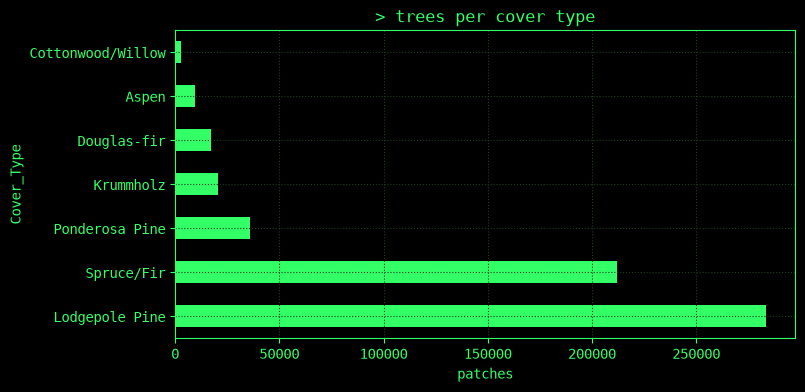

> CLASS BALANCE                        
┌───────────────────┬─────────┬───────┐
│ Cover_Type        │ patches │ share │
├───────────────────┼─────────┼───────┤
│ Lodgepole Pine    │  283301 │ 0.488 │
│ Spruce/Fir        │  211840 │ 0.365 │
│ Ponderosa Pine    │   35754 │ 0.062 │
│ Krummholz         │   20510 │ 0.035 │
│ Douglas-fir       │   17367 │ 0.030 │
│ Aspen             │    9493 │ 0.016 │
│ Cottonwood/Willow │    2747 │ 0.005 │
└───────────────────┴─────────┴───────┘

In [5]:
counts = df['Cover_Type'].map(COVER_NAMES).value_counts()
counts.plot(kind='barh', figsize=(8, 4), color=GREEN, title='> trees per cover type')
plt.xlabel('patches')
plt.show()
term_table(pd.DataFrame({'patches': counts, 'share': counts / counts.sum()}), 'CLASS BALANCE')

## 4. Train / test split
The full dataset has 581k rows. To keep training fast (also in Colab), we use a **stratified sample of 100,000 rows**, which keeps the same share of each cover type. 80% for training, 20% for testing.

In [6]:
sample = df.groupby('Cover_Type', group_keys=False).sample(frac=100_000 / len(df), random_state=42)
X = sample.drop(columns='Cover_Type')
y = sample['Cover_Type'] - 1  # XGBoost expects classes numbered from 0

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
term_panel('TRAIN / TEST SPLIT', [f'train : {len(X_train):,} rows', f'test  : {len(X_test):,} rows', f'features : {X.shape[1]}'])

┌─ TRAIN / TEST SPLIT ──┐
│ $ train : 80,000 rows │
│ $ test  : 20,001 rows │
│ $ features : 54       │
└───────────────────────┘

## 5. Train the models

In [7]:
def evaluate(model):
    pred = model.predict(X_test)
    return {'accuracy': accuracy_score(y_test, pred), 'macro F1': f1_score(y_test, pred, average='macro')}

rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42).fit(X_train, y_train)
xgb = XGBClassifier(n_estimators=400, max_depth=10, learning_rate=0.15, tree_method='hist',
                    n_jobs=-1, random_state=42).fit(X_train, y_train)

results = {'Random Forest': evaluate(rf), 'XGBoost': evaluate(xgb)}
term_table(pd.DataFrame(results).T, 'MODEL COMPARISON (TEST SET)')

> MODEL COMPARISON (TEST SET)          
┌───────────────┬──────────┬──────────┐
│               │ accuracy │ macro F1 │
├───────────────┼──────────┼──────────┤
│ Random Forest │    0.906 │    0.840 │
│ XGBoost       │    0.928 │    0.880 │
└───────────────┴──────────┴──────────┘

## 6. Bonus: hyperparameter tuning
Randomized search tries 8 Random Forest settings with 3-fold cross-validation on 30,000 training rows, then the best setting is retrained on the full training set.

In [8]:
search = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=-1, random_state=42),
    param_distributions={
        'n_estimators': [100, 200, 300],
        'max_depth': [None, 20, 30],
        'min_samples_split': [2, 5, 10],
        'max_features': ['sqrt', 0.3, 0.5],
    },
    n_iter=8, cv=3, scoring='accuracy', random_state=42,
)
search.fit(X_train[:30_000], y_train[:30_000])

rf_tuned = RandomForestClassifier(**search.best_params_, n_jobs=-1, random_state=42).fit(X_train, y_train)
results['Random Forest (tuned)'] = evaluate(rf_tuned)

term_panel('BEST PARAMETERS', [f'{k:<17}: {v}' for k, v in search.best_params_.items()])
results_df = pd.DataFrame(results).T.sort_values('accuracy', ascending=False)
term_table(results_df, 'ALL MODELS (TEST SET)')

┌─ BEST PARAMETERS ─────────┐
│ $ n_estimators     : 200  │
│ $ min_samples_split: 2    │
│ $ max_features     : 0.3  │
│ $ max_depth        : None │
└───────────────────────────┘

> ALL MODELS (TEST SET)                        
┌───────────────────────┬──────────┬──────────┐
│                       │ accuracy │ macro F1 │
├───────────────────────┼──────────┼──────────┤
│ XGBoost               │    0.928 │    0.880 │
│ Random Forest (tuned) │    0.919 │    0.860 │
│ Random Forest         │    0.906 │    0.840 │
└───────────────────────┴──────────┴──────────┘

## 7. Confusion matrix (best model)

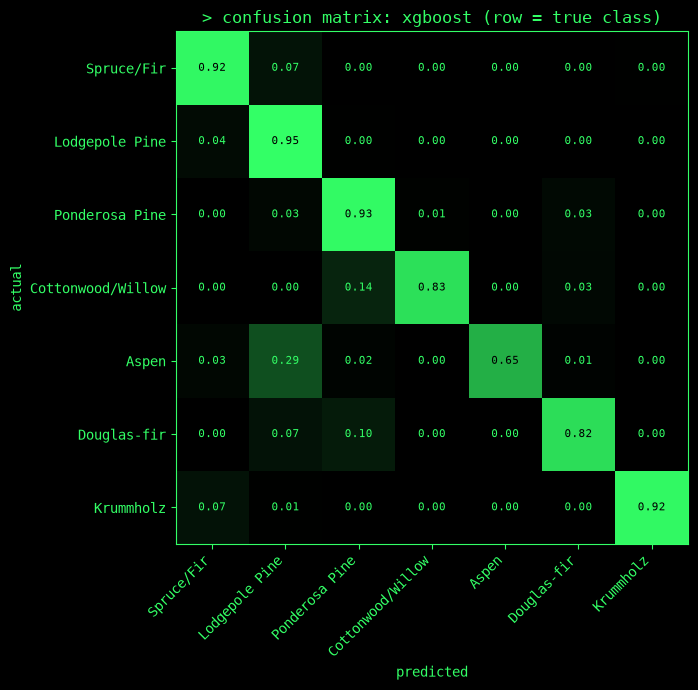

> PER-CLASS REPORT: XGBOOST                          
┌───────────────────┬───────────┬────────┬──────────┐
│                   │ precision │ recall │ f1-score │
├───────────────────┼───────────┼────────┼──────────┤
│ Spruce/Fir        │     0.935 │  0.923 │    0.929 │
│ Lodgepole Pine    │     0.930 │  0.949 │    0.940 │
│ Ponderosa Pine    │     0.905 │  0.929 │    0.917 │
│ Cottonwood/Willow │     0.849 │  0.832 │    0.840 │
│ Aspen             │     0.891 │  0.651 │    0.753 │
│ Douglas-fir       │     0.877 │  0.823 │    0.849 │
│ Krummholz         │     0.945 │  0.925 │    0.935 │
└───────────────────┴───────────┴────────┴──────────┘

In [9]:
best_name = results_df.index[0]
best_model = {'Random Forest': rf, 'XGBoost': xgb, 'Random Forest (tuned)': rf_tuned}[best_name]
pred = best_model.predict(X_test)
labels = [COVER_NAMES[i + 1] for i in range(7)]

cm = confusion_matrix(y_test, pred, normalize='true')
terminal_cmap = LinearSegmentedColormap.from_list('terminal', ['#000000', GREEN])
fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(cm, cmap=terminal_cmap)
ax.grid(False)
ax.set_xticks(range(7), labels, rotation=45, ha='right')
ax.set_yticks(range(7), labels)
for i in range(7):
    for j in range(7):
        ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', color='black' if cm[i, j] > 0.5 else GREEN, fontsize=8)
ax.set(title=f'> confusion matrix: {best_name.lower()} (row = true class)', xlabel='predicted', ylabel='actual')
plt.tight_layout()
plt.show()

report = pd.DataFrame(classification_report(y_test, pred, target_names=labels, output_dict=True)).T
term_table(report.loc[labels, ['precision', 'recall', 'f1-score']], f'PER-CLASS REPORT: {best_name.upper()}')

## 8. Feature importance

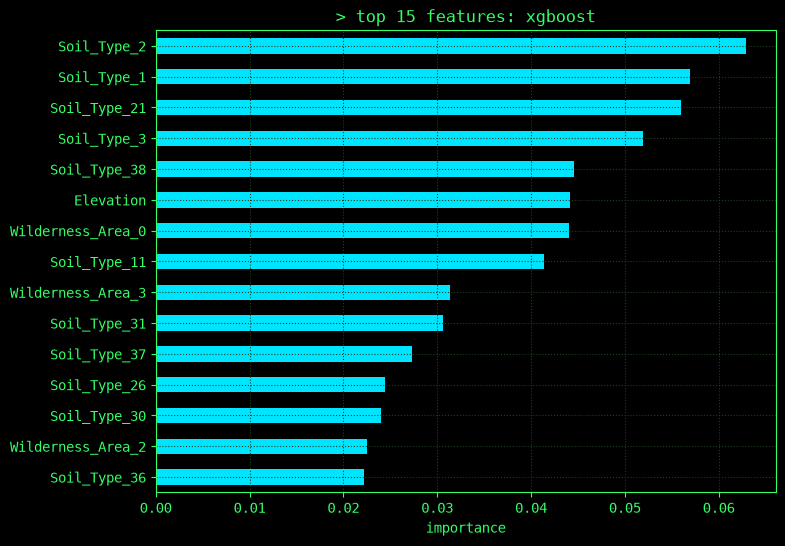

> TOP 10 FEATURES                 
┌───────────────────┬────────────┐
│                   │ importance │
├───────────────────┼────────────┤
│ Soil_Type_2       │      0.063 │
│ Soil_Type_1       │      0.057 │
│ Soil_Type_21      │      0.056 │
│ Soil_Type_3       │      0.052 │
│ Soil_Type_38      │      0.045 │
│ Elevation         │      0.044 │
│ Wilderness_Area_0 │      0.044 │
│ Soil_Type_11      │      0.041 │
│ Wilderness_Area_3 │      0.031 │
│ Soil_Type_31      │      0.031 │
└───────────────────┴────────────┘

In [10]:
importance = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
importance.sort_values().plot(kind='barh', figsize=(8, 6), color=CYAN, title=f'> top 15 features: {best_name.lower()}')
plt.xlabel('importance')
plt.show()
term_table(importance.head(10).to_frame('importance'), 'TOP 10 FEATURES')

## 9. Conclusions

- **Data:** 581,012 forest patches, 54 features, no missing values or duplicates. The categorical features (4 wilderness areas, 40 soil types) were already one-hot encoded, and every row has exactly one of each. The classes are very imbalanced: Lodgepole Pine and Spruce/Fir make up 85% of patches, Cottonwood/Willow only 0.5%. A stratified 100,000-row sample kept training fast.
- **Random Forest vs XGBoost (bonus):** XGBoost won with **92.8% accuracy (macro F1 0.880)** versus 90.6% (0.840) for the default Random Forest.
- **Hyperparameter tuning (bonus):** randomized search found `max_features=0.3, max_depth=None, n_estimators=200`, raising Random Forest to 91.9% accuracy (macro F1 0.860), still behind XGBoost.
- **Confusion matrix:** the big classes are predicted well (F1 0.93-0.94). The hardest class is **Aspen (recall 0.65)**, which is often confused with neighbouring types because it is rare in the data.
- **Feature importance:** soil types, elevation and wilderness area drive the predictions, so where a patch is matters most for which trees grow there.